In [1]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/shashanknecrothapa/ames-housing-dataset/AmesHousing.csv


In [2]:
import pandas as pd

data = pd.read_csv("/kaggle/input/datasets/shashanknecrothapa/ames-housing-dataset/AmesHousing.csv")

print(f"Total Rows: {data.shape[0]}\nTotal Column: {data.shape[1]}")

data.head()

Total Rows: 2930
Total Column: 82


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


Text(0.5, 1.0, 'Log1p SalePrice (Log Skew: -0.01)')

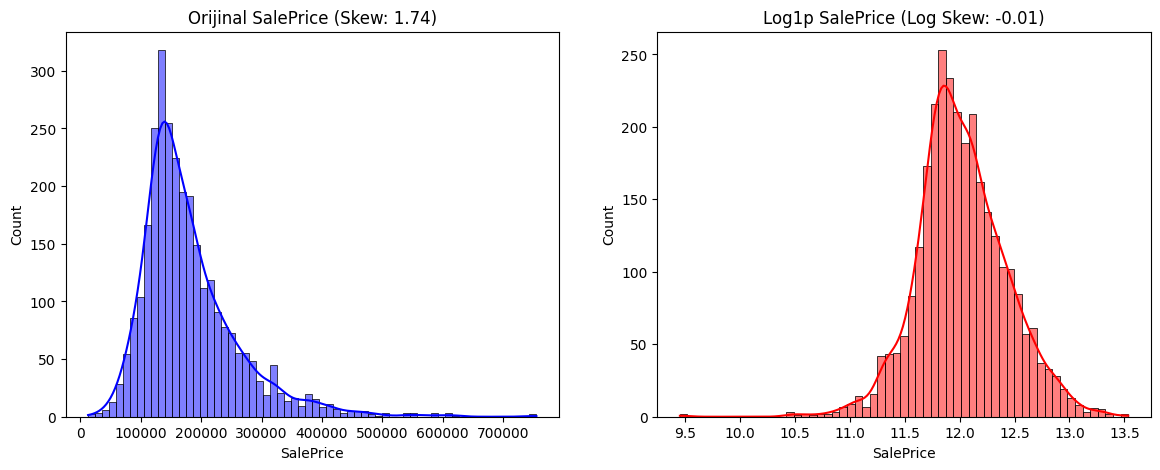

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data['SalePrice'], kde=True, ax=ax[0], color='blue')
ax[0].set_title(f"Orijinal SalePrice (Skew: {data["SalePrice"].skew():.2f})")

sns.histplot(np.log1p(data['SalePrice']), kde=True, ax=ax[1], color='red')
ax[1].set_title(f"Log1p SalePrice (Log Skew: {np.log1p(data["SalePrice"]).skew():.2f})")


In [4]:
print(data.columns)
print(data["Neighborhood"].nunique()) #28 is total num. We can use it
# Order, PID

Index(['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area',
       'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities',
       'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual',
       'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style',
       'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type',
       'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual',
       'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1',
       'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF',
       'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF',
       '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath',
       'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr',
       'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional',
       'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt',
      

In [5]:
data = data.drop(columns=["Order","PID"])

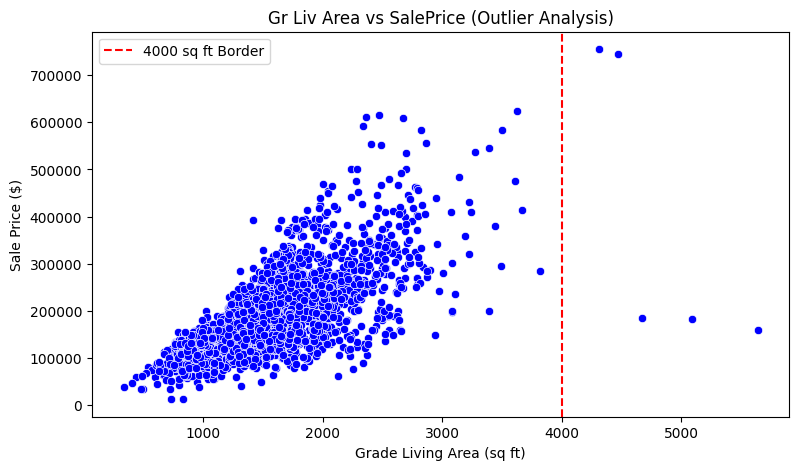

In [6]:
plt.figure(figsize=(9,5))
sns.scatterplot(data=data,x="Gr Liv Area", y="SalePrice", color="blue")
plt.axvline(x=4000,color="red",linestyle="--",label="4000 sq ft Border")
plt.title("Gr Liv Area vs SalePrice (Outlier Analysis)")
plt.xlabel("Grade Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.legend()